# 📱 Smartphone Price Analysis & Price-Prediction Model

**Objective:** Explore a cleaned smartphone specifications dataset, understand how
device features (brand, processor, RAM, storage, camera, connectivity, screen size,
etc.) relate to **price** and **user rating**, and then build/evaluate regression
models that can predict a phone's price from its specs. The final model and
preprocessing pipeline are exported for use in a deployment app.

**Notebook workflow**
1. Data loading & cleaning
2. Univariate analysis (price, rating, brand share, hardware specs)
3. Bivariate analysis (impact of brand / processor / connectivity on price & rating)
4. Correlation analysis
5. Missing-value imputation (KNN)
6. Feature engineering (one-hot encoding + scaling)
7. Model training & comparison (10 regression algorithms)
8. Final model evaluation & single-record prediction test
9. Exporting model artifacts (`.pkl`) and reference data for a deployment app

## 1. Setup

**What it does:** Imports the core data-analysis and visualization libraries
(`pandas`, `numpy`, `seaborn`, `matplotlib`), suppresses warning messages for
cleaner output, and configures pandas to display **all** rows/columns so nothing
gets truncated while exploring the data.

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)


## 2. Load the Dataset

**What it does:** Reads the cleaned smartphone dataset (`Clean2_Smart_Phones.csv`)
and drops the `Unnamed: 0` column — an artifact left over from a previous
`.to_csv()` export that saved the DataFrame's row index as a regular column.

In [58]:
df  = pd.read_csv("../data/Clean2_Smart_Phones.csv")
df.drop(columns="Unnamed: 0",inplace=True)

**What it does:** Resets the row index (creating a fresh `index` column) and
previews the first two rows — a quick sanity check that the data loaded correctly
and a first look at the available columns.

In [59]:
df  = df.reset_index()
df.head(2)

,index,Brand,model,price,Has_5G,Has_NFC,Has_IR_Blaster,Processor_Model,Processor_Name,Processor_Core,Processor_Speed,rating,Ram,Memory,Battery,Screen_size,Resolution,Num_Back_Cam,Back_Camera_MP,Front_CAM_MP,Num_Front_Cam,Refresh_Rate,Fast_Charge,OS_Name,os_version,card_support,slot_type,capacity_gb
0,0,Vertu,Vertu Signature Touch,650000,False,True,False,Snapdragon,Snapdragon 801,8.0,1.5,62,2.0,64.0,2275.0,4.70,1080 x 1920,1,13.0,2.1,1,60,NaN,Android,4.4,0,Not Slot,0
1,1,Xiaomi,Xiaomi Redmi K20 Pro Signature Edition,480000,False,True,False,Snapdragon,Snapdragon 855,8.0,2.8,88,8.0,256.0,4000.0,6.39,1080 x 2340,3,48.0,20.0,1,60,27.0,Android,9.0,0,Not Slot,0


**What it does:** Prints column names, data types, and non-null counts for every
column.

**Insight:** This is the first checkpoint to spot missing values and confirm that
numeric specs (price, RAM, battery, etc.) were loaded with the correct dtypes
before any analysis begins.

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 28 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   index            981 non-null    int64  
 1   Brand            981 non-null    str    
 2   model            981 non-null    str    
 3   price            981 non-null    int64  
 4   Has_5G           981 non-null    bool   
 5   Has_NFC          981 non-null    bool   
 6   Has_IR_Blaster   981 non-null    bool   
 7   Processor_Model  981 non-null    str    
 8   Processor_Name   981 non-null    str    
 9   Processor_Core   975 non-null    float64
 10  Processor_Speed  948 non-null    float64
 11  rating           981 non-null    int64  
 12  Ram              978 non-null    float64
 13  Memory           981 non-null    float64
 14  Battery          970 non-null    float64
 15  Screen_size      981 non-null    float64
 16  Resolution       981 non-null    str    
 17  Num_Back_Cam     981 non-nu

## 3. Univariate Analysis — Brand Market Share

**What it does:** Counts how many phones belong to each brand, takes the **top 5**
brands by frequency, and plots their share as a pie chart.

**Insight:** Shows which manufacturers dominate this catalog — useful context for
the brand-wise price/rating comparisons later in the notebook.

<Axes: >

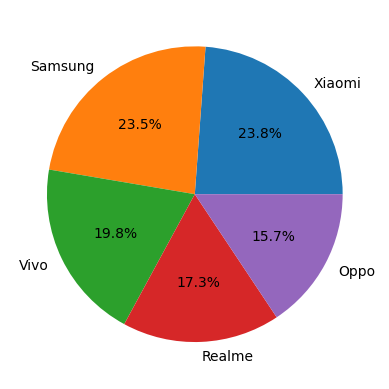

In [61]:
df["Brand"].value_counts().head(5).plot(kind="pie",autopct = "%0.1f%%")

## 4. Price Distribution

**What it does:** Generates summary statistics (mean, std, min/max, quartiles) for
the `price` column — the **target variable** for the prediction model.

In [62]:
df["price"].describe()

count       981.000000
mean      32494.386340
std       39520.105406
min        3499.000000
25%       12999.000000
50%       19990.000000
75%       35489.000000
max      650000.000000
Name: price, dtype: float64

**What it does:** Plots a histogram with a KDE (smoothed density curve) overlay for
`price`.

**Insight:** Reveals the overall shape of the price distribution — typically
right-skewed for phone prices, with most devices clustered at the budget/mid-range
and a long tail of expensive flagship/foldable models.

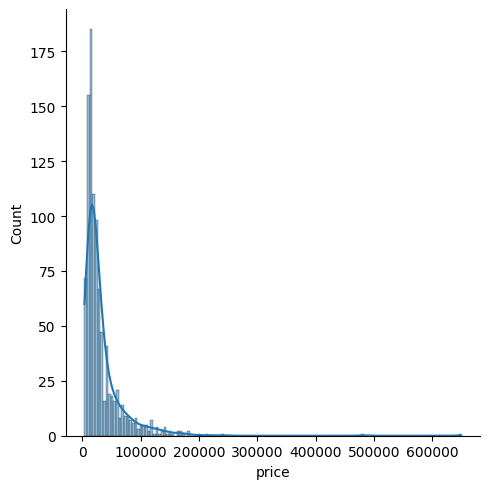

In [63]:
sns.displot(kind="hist",data=df,x="price",kde= True)

**What it does:** Calculates the skewness coefficient of `price` and draws a
boxplot.

**Insight:** A positive skew value confirms the right-skew seen above; the boxplot
highlights individual outlier devices (very high-priced phones) that sit far
beyond the upper whisker.

6.592612911141155


<Axes: ylabel='price'>

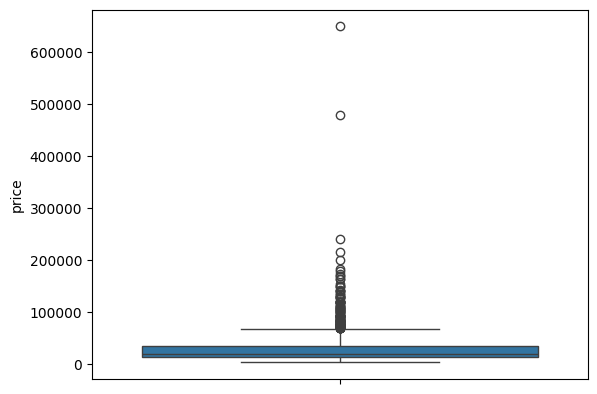

In [64]:
print(df["price"].skew())

sns.boxplot(df,y="price")

**What it does:** Filters and displays the rows where `price` exceeds **200,000** —
i.e., the extreme high-end outliers flagged by the boxplot.

**Insight:** Lets us inspect exactly which models/brands drive the long tail
(usually flagships or foldables), and decide whether they're genuine data points or
data-entry errors before modeling.

In [65]:
df[df["price"]>200000]

,index,Brand,model,price,Has_5G,Has_NFC,Has_IR_Blaster,Processor_Model,Processor_Name,Processor_Core,Processor_Speed,rating,Ram,Memory,Battery,Screen_size,Resolution,Num_Back_Cam,Back_Camera_MP,Front_CAM_MP,Num_Front_Cam,Refresh_Rate,Fast_Charge,OS_Name,os_version,card_support,slot_type,capacity_gb
0,0,Vertu,Vertu Signature Touch,650000,False,True,False,Snapdragon,Snapdragon 801,8.0,1.50,62,2.0,64.0,2275.0,4.70,1080 x 1920,1,13.0,2.1,1,60,NaN,Android,4.4,0,Not Slot,0
1,1,Xiaomi,Xiaomi Redmi K20 Pro Signature Edition,480000,False,True,False,Snapdragon,Snapdragon 855,8.0,2.80,88,8.0,256.0,4000.0,6.39,1080 x 2340,3,48.0,20.0,1,60,27.0,Android,9.0,0,Not Slot,0
2,2,Huawei,Huawei Mate 50 RS Porsche Design,239999,False,True,True,Snapdragon,Snapdragon 8+ Gen1,8.0,3.20,81,NaN,512.0,4700.0,6.74,1212 x 2616,3,50.0,13.0,1,120,66.0,Hongmeng,3.0,1,Hybird,256
3,3,Huawei,Huawei Mate 30 RS Porsche Design,214990,True,True,True,Kirin,Kirin 990,8.0,2.86,0,12.0,512.0,4500.0,6.53,1176 x 2400,4,40.0,32.0,2,60,40.0,Android,10.0,1,Hybird,256


## 5. Rating Column Cleaning

**What it does:** Replaces `0` values in the `rating` column with `NaN`, since a
rating of `0` most likely means *"no rating submitted"* rather than an actual score
of zero — treating it as missing data is more realistic and prevents it from
dragging down the average rating.

**⚠️ Code note:** `df['rating'] = df['rating'].replace({0: np.nan}, inplace=True)`
mixes `inplace=True` with reassignment. This pattern is unreliable across pandas
versions (older pandas returns `None` from the in-place call, which would overwrite
the whole column with `NaN`) and triggers a `ChainedAssignmentError` warning even
when it happens to work. The safer, version-proof form is:

```python
df['rating'] = df['rating'].replace({0: np.nan})
```

In [66]:
df["rating"] = df["rating"].replace({0:np.nan},inplace=True)

**What it does:** Re-runs `.describe()` on `rating` after the `0 → NaN` cleanup, so
the statistics now reflect only genuinely-rated phones.

In [67]:
df["rating"].describe()

count    879.000000
mean      78.258248
std        7.402854
min       60.000000
25%       74.000000
50%       80.000000
75%       84.000000
max       89.000000
Name: rating, dtype: float64

**What it does:** Plots the distribution of `rating` (histogram + KDE) and prints
its skewness.

**Insight:** Ratings cluster in a narrower, more normal-looking range (roughly
60–89 here) compared to price, since user ratings are bounded and less extreme.

-0.6989993034105535

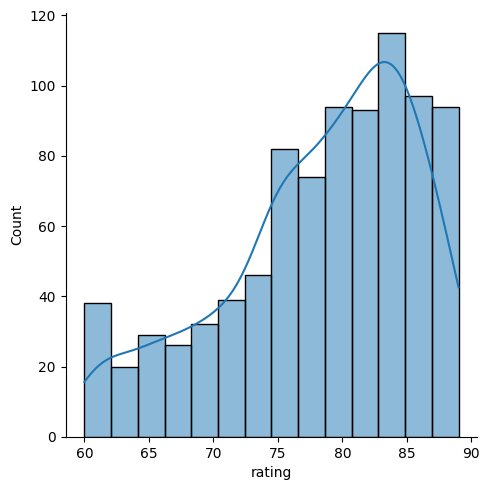

In [68]:
sns.displot(kind="hist",data = df,x= "rating",kde =True)
df["rating"].skew()

**What it does:** Boxplot of `rating` to visually confirm the spread and check for
any remaining outliers after the cleaning step.

<Axes: ylabel='rating'>

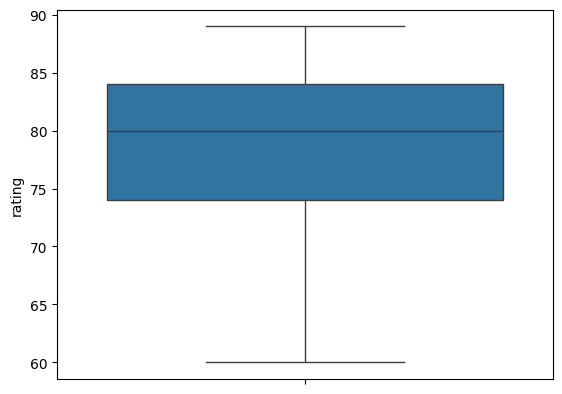

In [69]:
sns.boxplot(data = df,y= "rating")

## 6. Connectivity Features — 5G, IR Blaster, NFC

**What it does:** Pie chart showing what proportion of phones in the dataset
support **5G**.

**Insight:** Gives a quick sense of how mainstream 5G has become in this catalog —
a feature later tested for its effect on price (see Cell 30 / the `Has_5G` vs.
price plot).

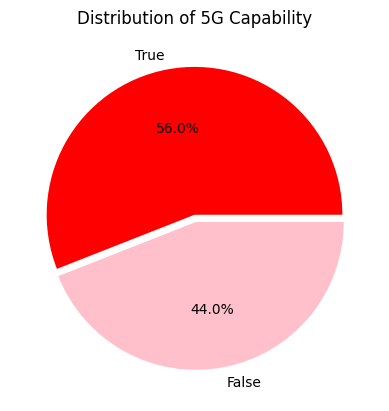

In [70]:
counts = df["Has_5G"].value_counts()
plt.pie(counts,labels=counts.index,explode=[0.01,0.04],autopct="%0.1f%%",colors=["red","pink"])
plt.title('Distribution of 5G Capability')
plt.show()

**What it does:** Pie chart of the proportion of phones with an **IR Blaster**
(used for infrared remote-control functionality).

**Insight:** IR Blasters are a comparatively rare feature, often concentrated in a
specific subset of brands — a useful "brand fingerprint" feature.

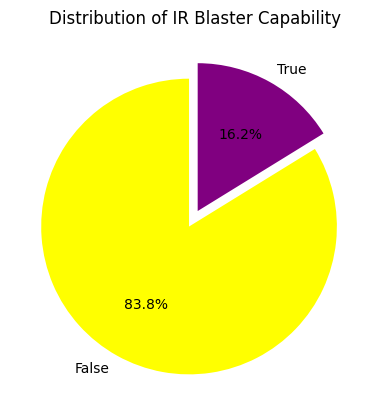

In [71]:
counts = df["Has_IR_Blaster"].value_counts()
plt.pie(counts,labels=counts.index,explode=[0.08,0.04],autopct="%0.1f%%",colors=["yellow","purple"],startangle=90)
plt.title('Distribution of IR Blaster Capability')
plt.show()

**What it does:** Pie chart of the proportion of phones supporting **NFC** (used
for contactless payments / file transfer).

**Insight:** NFC tends to be more common on mid-to-high-end devices, which is
explored later as a price-driver (Cell 32).

Text(0.5, 1.0, 'Distribution of NFC Capability')

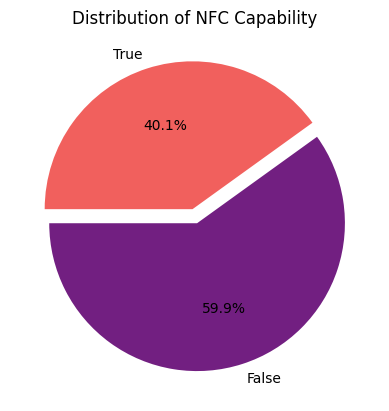

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get the counts
counts = df["Has_NFC"].value_counts()

colors = sns.color_palette("magma", len(counts))

# 3. Create the pie chart
plt.pie(
    counts, 
    labels=counts.index, 
    explode=[0.05, 0.05], # Slight separation for all slices
    autopct="%0.1f%%", 
    colors=colors,        # Fixed parameter name
    startangle=180
)

plt.title('Distribution of NFC Capability')


## 7. Processor Name Cleaning

**What it does:**
1. Splits the `Processor_Model` string on commas and keeps only the first part
   (e.g., `"Snapdragon, 8 Gen 2"` → `"Snapdragon"`).
2. Fixes the typo `"Sanpdragon"` → `"Snapdragon"`.
3. Prints the resulting value counts.
4. Handles a special case: rows where the model code `"Sc9863a"` was mistakenly
   stored as the *brand* — these get moved into `Processor_Name` as
   `"Unisoc SC9863A"`, and `Processor_Model` is corrected to `"Unisoc"`.

**Insight:** Real-world scraped specs data is messy — chipset names appear with
inconsistent casing, typos, and mixed brand/model fields. This step standardizes
them into clean, comparable categories (Snapdragon, Helio, Dimensity, Unisoc,
Exynos, etc.) needed for the bivariate analysis and one-hot encoding later.

**⚠️ Code note:** the `"Sanpdragon"` → `"Snapdragon"` line again uses the
`inplace=True` + reassignment pattern flagged in Cell 9 — the safer alternative is
`df['Processor_Model'] = df['Processor_Model'].replace({'Sanpdragon': 'Snapdragon'})`.

In [73]:
df["Processor_Model"] = df["Processor_Model"].str.split(",").str.get(0)
df["Processor_Model"] = df["Processor_Model"].replace({"Sanpdragon":"Snapdragon"},inplace=True)
print(df["Processor_Model"].value_counts())

temp_df = df[df["Processor_Model"] == "Sc9863a"]   ### There is two processor half written so transform to full name to model or name of procesor
df.loc[temp_df.index,"Processor_Name"] = "Unisoc SC9863A"   
df.loc[temp_df.index,"Processor_Model"]=  "Unisoc"

Processor_Model
Snapdragon    418
Helio         204
Dimensity     178
Unisoc         59
Exynos         56
Bionic         41
Tensor          9
Kirin           8
A13             5
Sc9863a         2
Tesla           1
Name: count, dtype: int64


### There is some iphone model that written like A13 Bionic so simply reverse than like Bionic A13 enusring consistency

**What it does:** For rows where `Processor_Model == "A13"` (Apple's A13 Bionic,
originally stored as `"A13 Bionic"`), it **reverses the word order** in
`Processor_Name` (→ `"Bionic A13"`) and relabels `Processor_Model` as `"Bionic"`,
matching the naming convention already used for other Apple chips (e.g.,
`"A16 Bionic"`).

**Insight:** Comparing the value-count print *before* and *after*, the 5 `A13`
entries merge into the `Bionic` group (41 → 46), giving one consistent category for
Apple's Bionic-series chips.

**⚠️ Code note:** same `inplace=True` + reassignment pattern as before — works here
on recent pandas, but `df['Processor_Model'] = df['Processor_Model'].replace({'A13': 'Bionic'})`
is the recommended, version-safe form.

In [74]:
print(df["Processor_Model"].value_counts())
# Split the string, reverse the list, and join it back together
temp_df = df[df["Processor_Model"] =="A13"]
df.loc[temp_df.index,"Processor_Name"] = temp_df["Processor_Name"].apply(lambda x : " ".join(x.split()[::-1]))
#df["Processor_A16"].apply(lambda x: " ".join(x.split()[::-1]))
df["Processor_Model"] = df["Processor_Model"].replace({"A13":"Bionic"},inplace=True)

df["Processor_Model"].value_counts()

Processor_Model
Snapdragon    418
Helio         204
Dimensity     178
Unisoc         61
Exynos         56
Bionic         41
Tensor          9
Kirin           8
A13             5
Tesla           1
Name: count, dtype: int64


Processor_Model
Snapdragon    418
Helio         204
Dimensity     178
Unisoc         61
Exynos         56
Bionic         46
Tensor          9
Kirin           8
Tesla           1
Name: count, dtype: int64

## 8. Processor Brand Market Share

**What it does:** Pie chart of the **top 6** most common processor
brands/models (by count).

**Insight:** Highlights which chipset makers (Snapdragon, Helio, Dimensity, etc.)
dominate the catalog — sets up the price/rating comparisons by processor done
later (Cells 35 & 37).

Text(0.5, 1.0, 'Distribution of Processor Brand Capability')

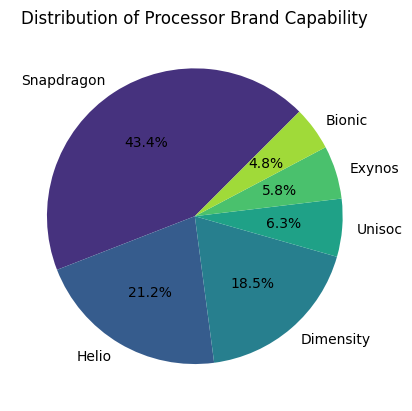

In [75]:
count = df["Processor_Model"].value_counts().head(6)
colors  = sns.color_palette("viridis",len(count))
plt.pie(count,labels=count.index,startangle=45,colors=colors,autopct="%0.1f%%")
plt.title('Distribution of Processor Brand Capability')

## 9. RAM Capacity Distribution

**What it does:** Pie chart of the **6 most common RAM sizes** across phones in
the dataset.

**Insight:** Shows which RAM tiers (e.g., 4GB, 6GB, 8GB) are most prevalent —
useful for understanding the dataset's overall market-segment skew (budget vs.
flagship).

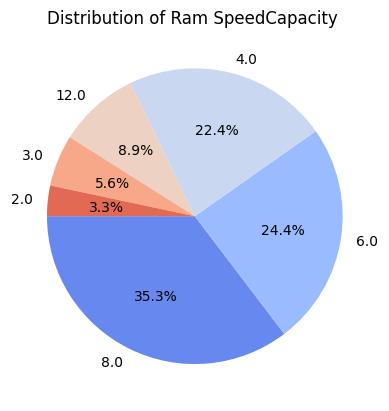

In [76]:
count = df["Ram"].value_counts().head(6)
colors  = sns.color_palette("coolwarm",len(count))
plt.pie(count,labels=count.index,startangle=180,colors=colors,autopct="%0.1f%%")
plt.title('Distribution of Ram SpeedCapacity ')
plt.show()

## 10. Storage (Memory) Distribution

**What it does:** Bar chart showing how many phones have each internal storage
capacity (in GB), sorted by storage size.

**Insight:** Reveals the most common storage configurations — typically a handful
of standard tiers (e.g., 64 / 128 / 256 GB) dominate the catalog.

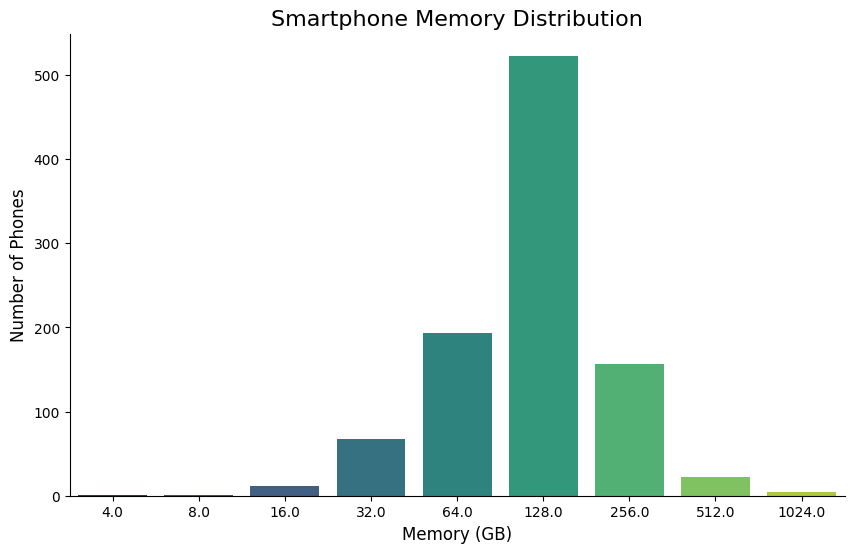

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare the data
counts = df['Memory'].value_counts().sort_index()

# 2. Create a colorful bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=counts.index, y=counts.values, palette="viridis")

# 3. Add just the essential labels
plt.title('Smartphone Memory Distribution', fontsize=16)
plt.xlabel('Memory (GB)', fontsize=12)
plt.ylabel('Number of Phones', fontsize=12)

# 4. Clean the background
sns.despine() 
plt.show()

## 11. Camera Configuration

**What it does:** Bar chart of how many phones have 1, 2, 3, or 4 rear cameras.

**Insight:** Multi-camera setups (2–3 lenses) are the most common configuration in
modern smartphones — this chart should confirm that pattern in the dataset.

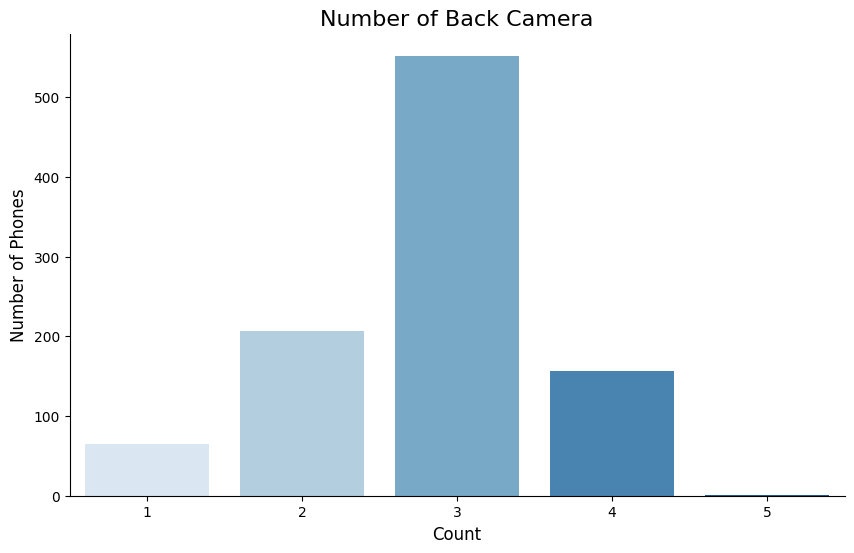

In [78]:
num_cam = df["Num_Back_Cam"].value_counts().sort_index()
plt.figure(figsize=(10, 6))
sns.barplot(x=num_cam.index, y=num_cam.values, palette="Blues")

# 3. Add just the essential labels
plt.title('Number of Back Camera', fontsize=16)
plt.xlabel('Count', fontsize=12)
plt.ylabel('Number of Phones', fontsize=12)

# 4. Clean the background
sns.despine() 
plt.show()


## 12. SIM / Memory Slot Type

**What it does:** Pie chart of the distribution of `slot_type` values (e.g.,
dual-SIM, dual-SIM + SD card, single-SIM).

**Insight:** Indicates how common expandable storage and dual-SIM support are —
both can be relevant price/feature differentiators in the model.

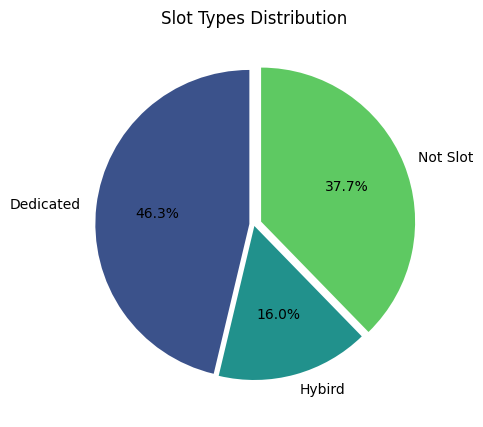

In [79]:
slot = df["slot_type"].value_counts().sort_index()
color  = sns.color_palette("viridis",len(slot))
plt.figure(figsize=(8,5))
plt.pie(data = df,x=slot,labels=slot.index,explode = [0.03,0.01,0.05],startangle=90,autopct="%0.1f%%",colors=color)
plt.title("Slot Types Distribution")
plt.show()

## 13. Reusable Plotting Helper

**What it does:** Defines a small helper function `plot(col)` that, for any
numeric column, draws a histogram + KDE and a separate boxplot.

**Insight:** Avoids repeating the same plotting code for every numeric feature — a
clean, reusable pattern for batch univariate analysis.

In [80]:
def plot(col):
    # Pass the dataframe with the 'data' parameter
    sns.displot(data=df, x=col, kind="hist", kde=True, label=col)
    sns.catplot(data=df, x=col, kind="box")
    plt.show()  

**What it does:** Selects a specific subset of numeric columns (by position) —
likely battery capacity, screen size, RAM, refresh rate and camera megapixels —
and runs the `plot()` helper on each one.

**Insight:** Produces a quick visual audit of every key hardware spec's
distribution and outliers in one pass, guiding decisions about scaling and outlier
handling before modeling.

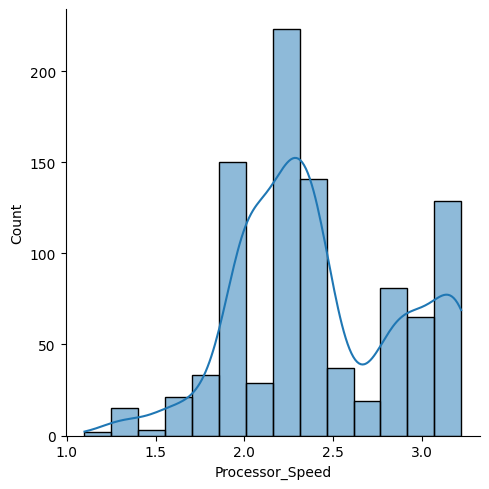

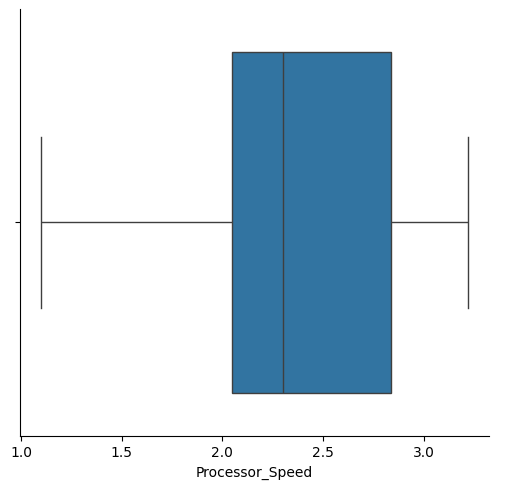

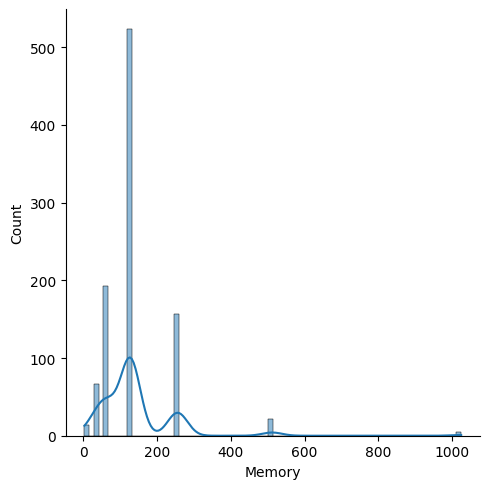

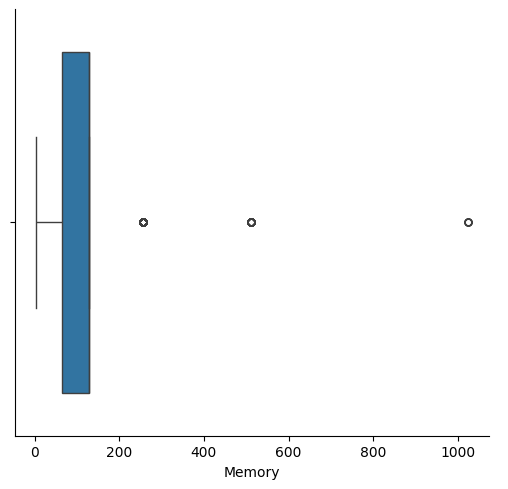

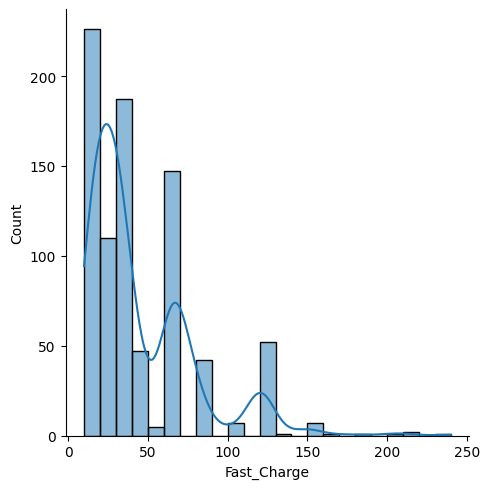

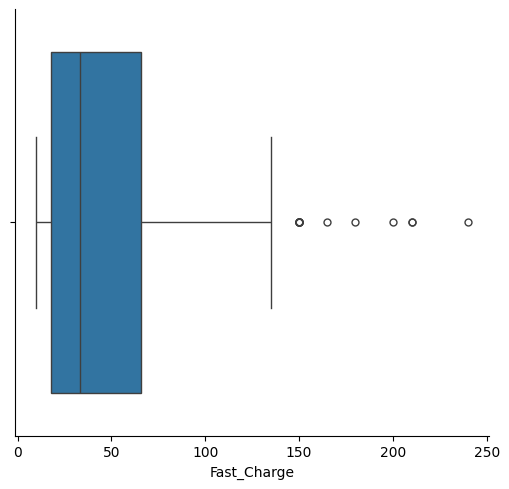

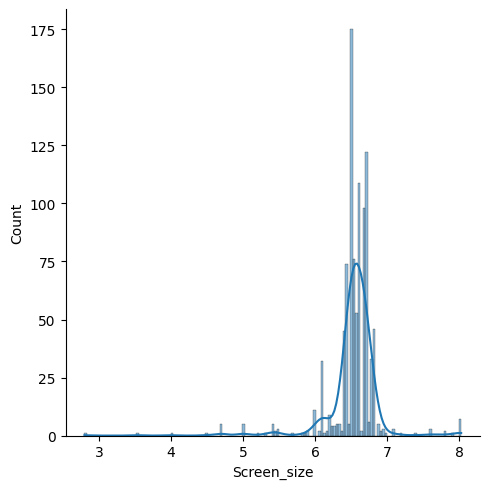

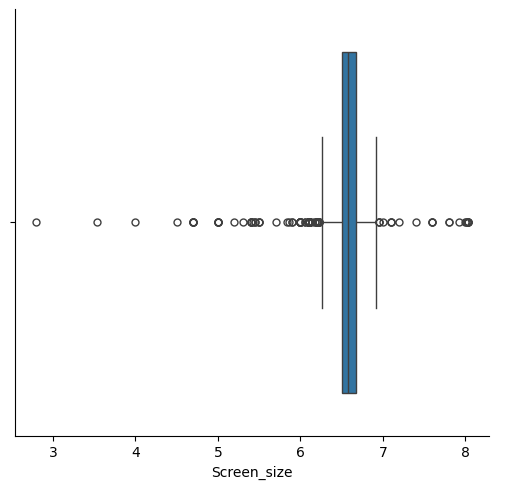

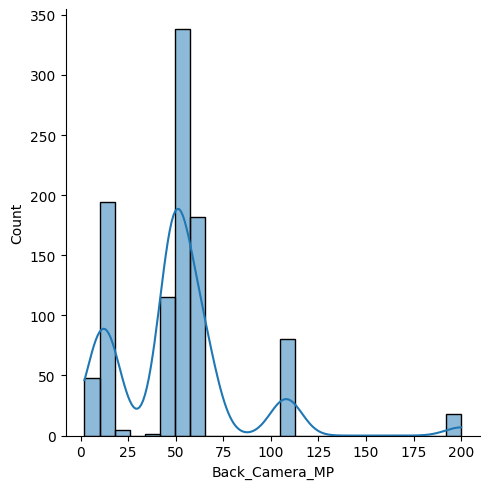

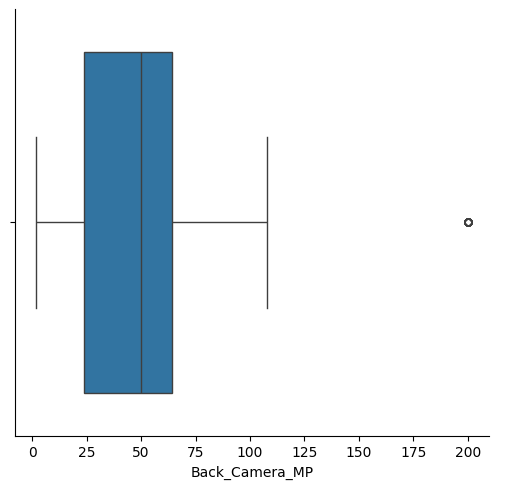

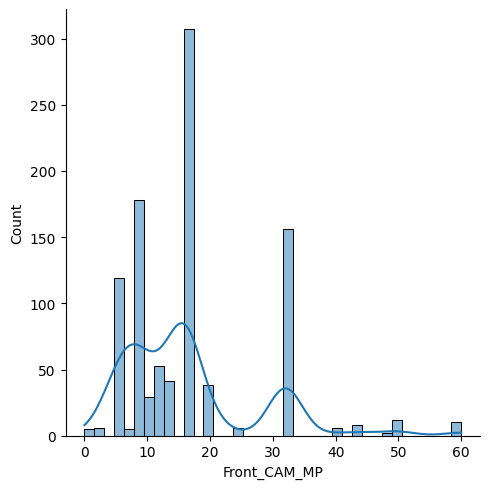

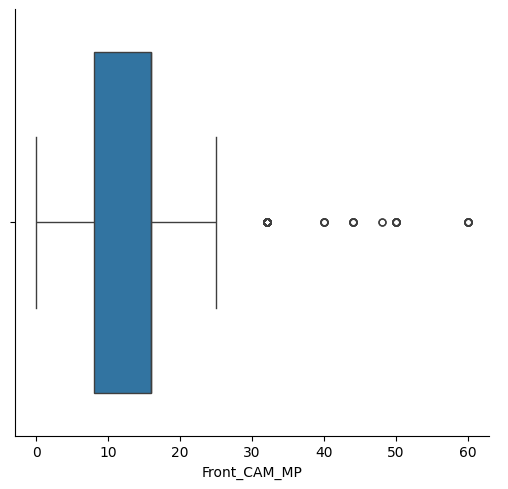

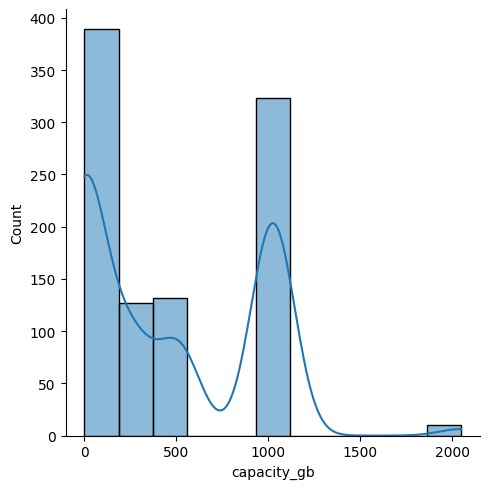

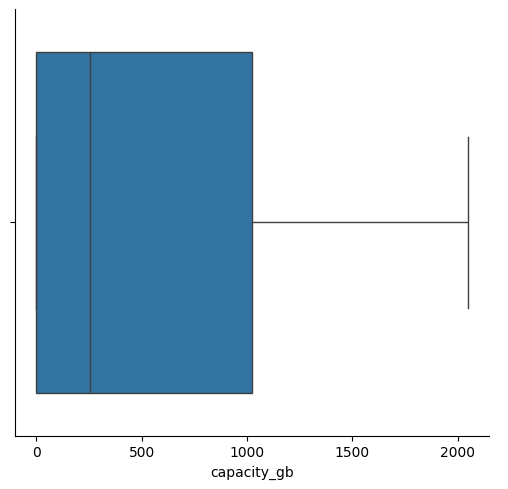

In [81]:
num_coloumns = df.select_dtypes(include=["float64","int64"]).iloc[:,[3,6,14,8,10,11,17]].columns


for col in num_coloumns:
    plot(col)

#### Biavariate Analysis

**What it does:** Standardizes the `Brand` column by capitalizing the first letter
of each brand name (e.g., `"samsung"` → `"Samsung"`), so the same brand isn't split
into multiple categories due to inconsistent casing.

In [82]:
df["Brand"] = df["Brand"].str.capitalize()


## 14. Brand vs. Price

**What it does:** Finds the **8 most frequent brands**, then plots their average
`price` as a bar chart.

**Insight:** Directly shows which brands command a price premium versus
budget-oriented brands — a strong candidate signal for the model, and the basis
for the one-hot encoded `Brand` feature used later.

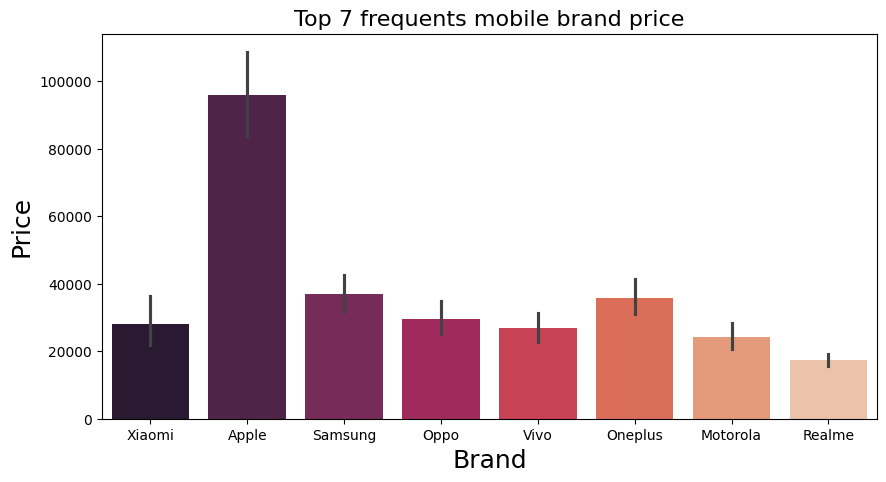

In [83]:
temp_df_counts = df.groupby("Brand").count()["model"].sort_values(ascending=False).head(8) 
temp_df = df[df["Brand"].isin(temp_df_counts.index)]

plt.figure(figsize=(10, 5))

# Plotting
sns.barplot(data=temp_df, x="Brand", y="price", palette="rocket", hue="Brand", legend=False)




# Also adjusting the Y-axi
plt.xlabel("Brand", fontsize=18)
plt.ylabel("Price", fontsize=18)
plt.title("Top 7 frequents mobile brand price",fontsize = 16)

plt.show()


**What it does:** Plots the average `rating` for the same set of top brands
(y-axis zoomed to 70–85 for readability).

**Insight:** Lets us check whether higher-priced brands also receive higher user
ratings, or whether price and perceived quality diverge for any brand.

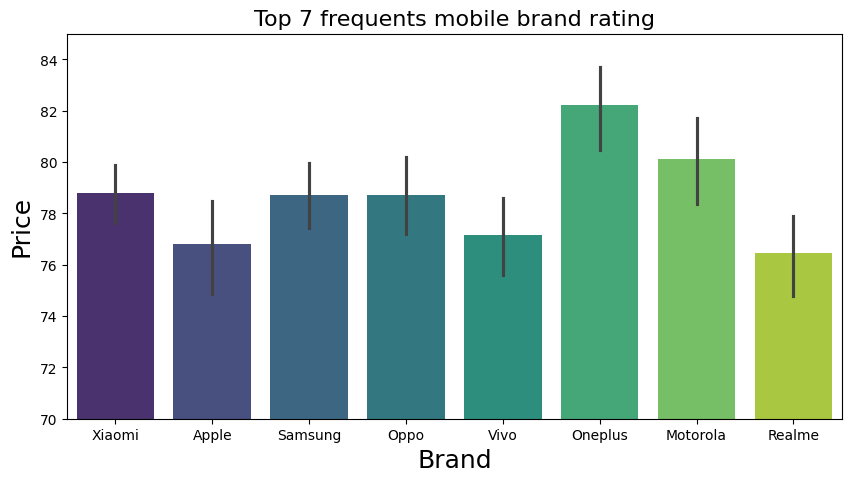

In [84]:
plt.figure(figsize=(10, 5))

# Plotting
sns.barplot(data=temp_df, x="Brand", y="rating", palette="viridis", hue="Brand", legend=False)
# Also adjusting the Y-axi
plt.ylim(70,85)
plt.xlabel("Brand", fontsize=18)
plt.ylabel("Price", fontsize=18)
plt.title("Top 7 frequents mobile brand rating",fontsize = 16)

plt.show()


## 15. Feature Impact on Price — 5G

**What it does:** Point plot comparing the **mean price** of phones with vs.
without 5G support.

**Insight:** Quantifies the price premium associated with 5G connectivity —
typically a sizeable gap, since 5G is still concentrated in mid-to-high-end
devices.

<Axes: xlabel='Has_5G', ylabel='price'>

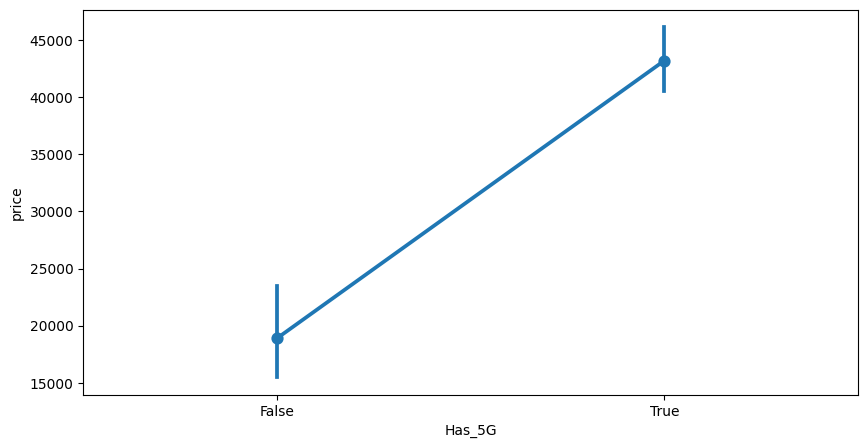

In [85]:
plt.figure(figsize=(10, 5))
sns.pointplot(data=df,x="Has_5G",y="price",estimator=np.mean)

#### Simple Indicate Mobile which have NFC Has higher price

**What it does:** Bar chart comparing the **mean price** for phones with vs.
without NFC — confirming the insight stated above.

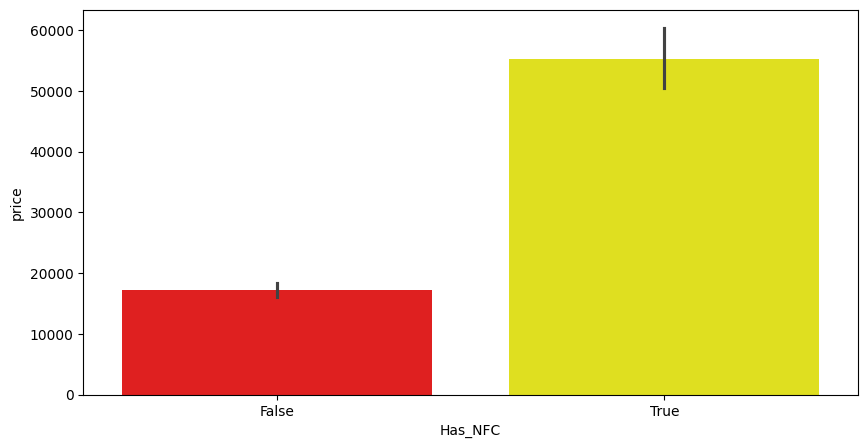

In [86]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df,x = "Has_NFC",y = "price",palette=["red","yellow"],estimator=np.mean)
plt.show()

## 16. Feature Impact on Price — IR Blaster

**What it does:** Violin plot comparing the full `price` **distribution** (not just
the mean) for phones with vs. without an IR Blaster.

**Insight:** A violin plot shows shape and spread, not just averages — useful for
spotting whether one group has a wider price range or a bimodal distribution that a
simple bar chart would hide.

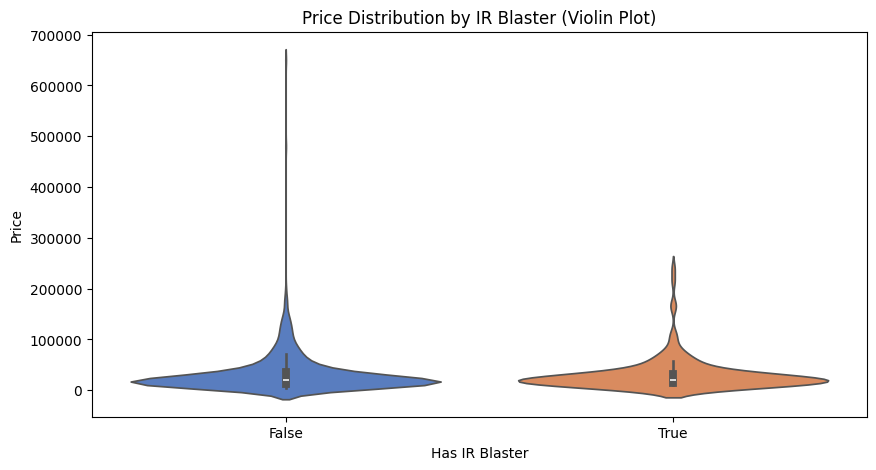

In [87]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="Has_IR_Blaster", y="price", palette="muted")
plt.title("Price Distribution by IR Blaster (Violin Plot)")
plt.ylabel("Price")
plt.xlabel("Has IR Blaster")
plt.show()

#### Processor that have huge price
1. Bionic 
#### Processor with low price
1. Unisoc

**What it does:** Filters to processor models with **more than 6 occurrences**
(to avoid noisy single-sample categories), then plots their average `price`.

**Insight:** Confirms the finding above — chipsets like Bionic (Apple) sit at the
high end of the price spectrum, while Unisoc sits at the low end, reflecting their
use in flagship vs. budget devices respectively.

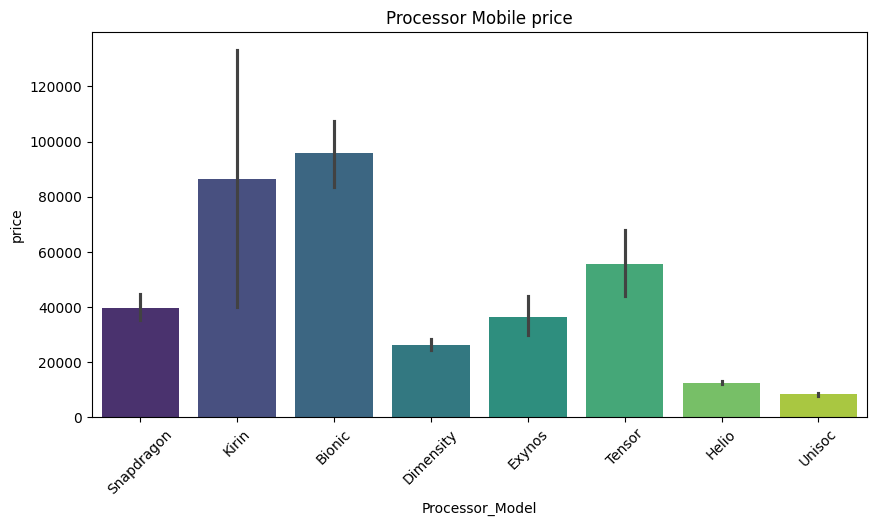

In [88]:
y = df.groupby("Processor_Model").count()["model"] 
temp_df1 =y[y> 6]
plt.figure(figsize=(10, 5))
process  = df[df["Processor_Model"].isin(temp_df1.index)]
sns.barplot(data= process,x="Processor_Model",y="price",hue="Processor_Model", # Assigns color per processor
    palette="viridis",     
    legend=False)
plt.title("Processor Mobile price")
plt.xticks(rotation=45)
plt.show()

#### Processor with good ratings are
1. SnapDragon
2. Dimensity
3. Helio

### Processor with low rating
1. Unisoc

**What it does:** Same filtered processor group as the previous chart, but plotting
average `rating` instead of `price` (y-axis zoomed to 60–88).

**Insight:** Confirms that premium chipsets (Snapdragon, Dimensity, Helio)
correlate with higher user satisfaction, while Unisoc-powered (budget) devices
score lower.

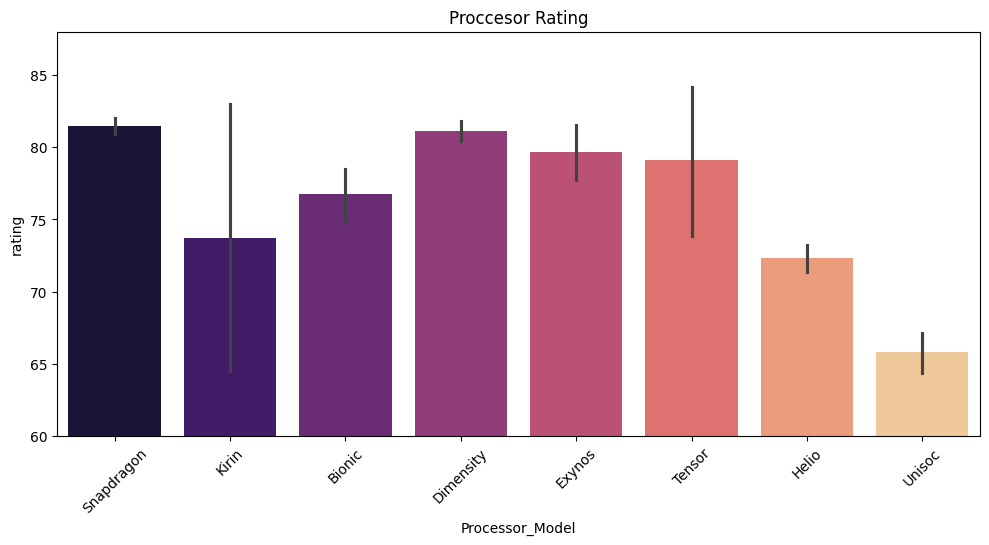

In [89]:

plt.figure(figsize=(10, 5))
sns.barplot(data= process,x="Processor_Model",y="rating",hue="Processor_Model", 
    palette="magma",     
    legend=False)
plt.title("Proccesor Rating")
plt.tight_layout()
plt.xticks(rotation=45)
plt.ylim(60,88)
plt.show()

# Processor Cores Market Segmentation

## Performance Tiers

### 4 Core Processors
- **Price Status:** Lowest
- **Rating Status:** Lowest
- **Market Position:** Budget / Entry
- **Target Audience:** Basic users, entry-level smartphones

### 6 Core Processors
- **Price Status:** Highest
- **Rating Status:** Mid-High
- **Market Position:** High-End / Premium
- **Target Audience:** Premium users seeking balance

### 8 Core Processors
- **Price Status:** High
- **Rating Status:** Highest
- **Market Position:** Enthusiast / Performance
- **Target Audience:** Power users, gaming, multitasking

---



## 17. Combined View — Price & Rating by Processor Core Count

**What it does:** Creates a dual-axis chart: bars show average `price` (left axis)
and a line shows average `rating` (right axis), grouped by `Processor_Core`
(4 / 6 / 8-core).

**Insight:** Visualizes the price-vs-rating tradeoff across core-count tiers in a
single chart, directly illustrating the market segmentation summarized in the
markdown cell above (budget 4-core → premium 6/8-core).

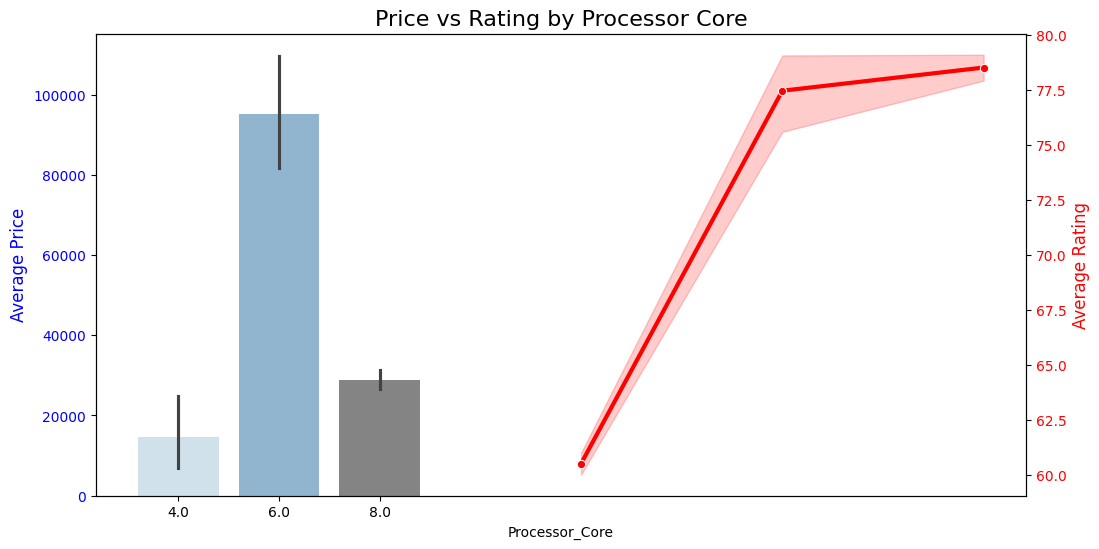

In [90]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar plot for Price
sns.barplot(data=temp_df, x="Processor_Core", y="price", alpha=0.6, ax=ax1, palette="Blues_d", hue="Processor_Core", legend=False)
ax1.set_ylabel("Average Price", fontsize=12, color="blue")
ax1.tick_params(axis='y', labelcolor="blue")

# Line plot for Rating (Secondary Axis)
ax2 = ax1.twinx()
sns.lineplot(data=temp_df, x="Processor_Core", y="rating", marker="o", color="red", ax=ax2, linewidth=3)
ax2.set_ylabel("Average Rating", fontsize=12, color="red")
ax2.tick_params(axis='y', labelcolor="red")

plt.title("Price vs Rating by Processor Core", fontsize=16)
plt.show()

### Replaceing low 5 os that are low frequent with other

**What it does:** Identifies the **5 least-frequent values** in `OS_Name`,
relabels them as `"other"`, then lowercases all OS names for consistency.

**Insight:** Reduces a long tail of rare/niche operating systems into a single
`other` bucket, producing a clean, low-cardinality categorical feature (`android`,
`ios`, `other`) suitable for one-hot encoding — and prevents the model from
overfitting to OS values that appear only once or twice.

**⚠️ Code note:** the loop again uses
`df['OS_Name'] = df['OS_Name'].replace({i: 'other'}, inplace=True)` — same
`inplace` + reassignment caveat as earlier cells; dropping `inplace=True` is the
safer, version-proof form.

In [91]:

idx  = df["OS_Name"].value_counts().tail(5).index

for i in idx:
    df["OS_Name"] = df["OS_Name"].replace({i:"other"},inplace=True)
df["OS_Name"] = df["OS_Name"].str.lower()
df["OS_Name"].value_counts()

OS_Name
android    925
ios         46
other       10
Name: count, dtype: int64


# Processor Core Distribution by Operating System

## Key Findings

- **Android devices predominantly use 8-core processors** .
- **iOS devices favor 6-core processors** 
```

**What it does:** Builds a cross-tabulation of `Processor_Core` vs. `OS_Name`,
normalized as **column percentages**, and visualizes it as a stacked bar chart.

**Insight:** Directly supports the finding in the markdown cell above — shows what
percentage of Android vs. iOS devices use each core-count tier, confirming
Android's 8-core dominance and iOS's 6-core preference.

<Figure size 1200x600 with 0 Axes>

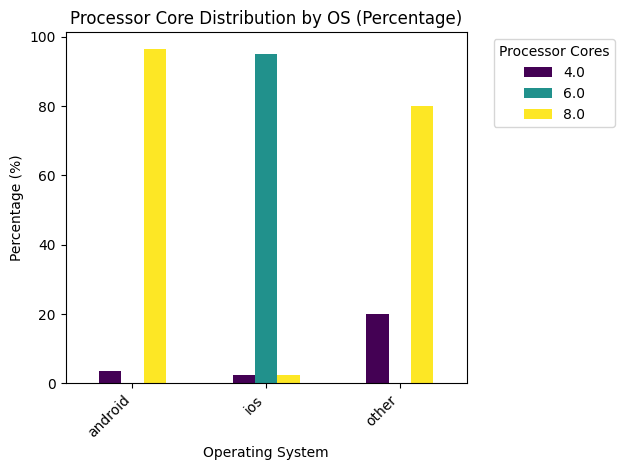

In [92]:

crosstab_data = round(pd.crosstab(df["Processor_Core"], df["OS_Name"], normalize="columns") * 100, 2)

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
crosstab_data.T.plot(kind="bar", colormap="viridis")
plt.title("Processor Core Distribution by OS (Percentage)")
plt.xlabel("Operating System")
plt.ylabel("Percentage (%)")
plt.legend(title="Processor Cores", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 18. Processor Speed vs. Price

**What it does:** Groups phones by `Processor_Speed` (GHz), computes the mean
`price` for each speed value, and plots it as a scatter plot.

**Insight:** Examines whether higher clock speeds translate to higher prices —
generally expected to trend upward, though with some noise since clock speed alone
doesn't fully determine a chipset's overall tier.

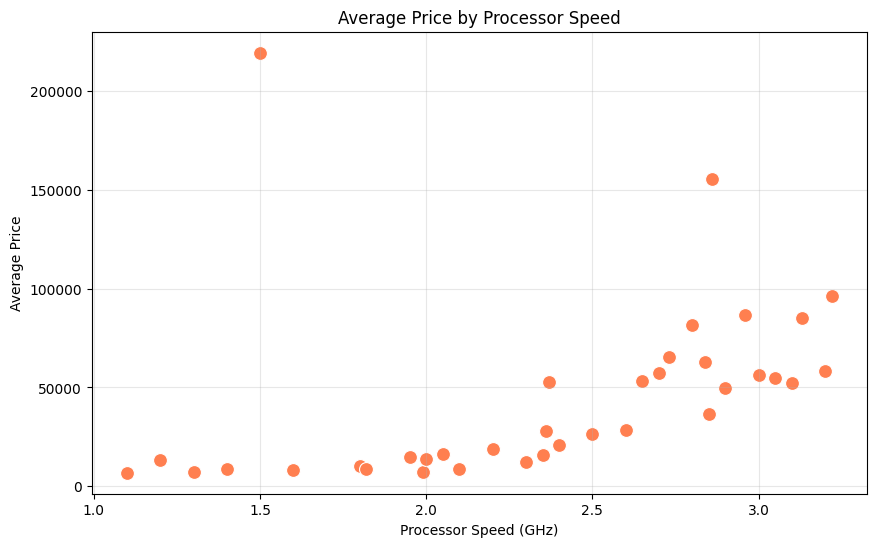

In [93]:
# Calculate mean price by processor speed
speed_price = round(df.groupby("Processor_Speed")["price"].mean(), 2)

# Create scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=speed_price.index, y=speed_price.values, s=100, color='coral')
plt.title("Average Price by Processor Speed")
plt.xlabel("Processor Speed (GHz)")
plt.ylabel("Average Price")
plt.grid(alpha=0.3)
plt.show()

## 19. Screen Size vs. Rating

**What it does:** Groups phones by `Screen_size`, computes the mean `rating` for
each size (dropping sizes with no rating data), and plots it as a scatter plot.

**Insight:** Checks whether users rate certain screen sizes more favorably — useful
for spotting a "sweet spot" screen size that correlates with higher satisfaction.

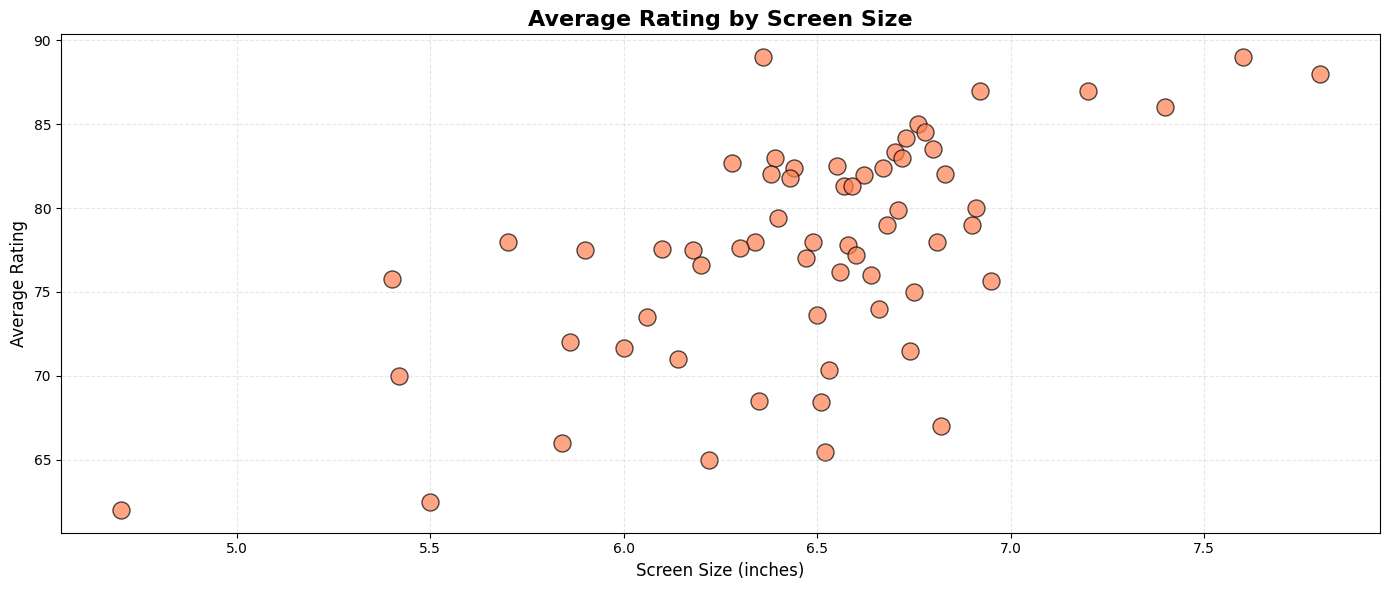

In [94]:
# Get screen sizes that have non-null mean ratings
valid_screen_sizes = df.groupby("Screen_size")["rating"].mean().dropna().index
df_filtered = df[df["Screen_size"].isin(valid_screen_sizes)]
temp_df = round(df_filtered.groupby("Screen_size")["rating"].mean(), 2).sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.scatterplot(x=temp_df.index, y=temp_df.values, s=150, color='coral', edgecolor='black', alpha=0.7)

plt.title("Average Rating by Screen Size", fontsize=16, fontweight='bold')
plt.xlabel("Screen Size (inches)", fontsize=12)
plt.ylabel("Average Rating", fontsize=12)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## 20. Pre-Modeling Cleanup

**What it does:** Drops the temporary `index` column (created back in Cell 2),
since it carries no predictive information and would otherwise be treated as a
numeric feature by the model.

In [95]:
# Drop the index column
df.drop(columns=["index"], inplace=True)

## 21. Correlation Analysis

**What it does:** Computes the pairwise correlation matrix for all numeric columns
and visualizes it as a heatmap.

**Insight:** Identifies which numeric specs (RAM, battery, screen size, camera MP,
etc.) are most strongly correlated with `price` — the strongest candidates for
predictive features — while also flagging multicollinearity between features
(e.g., RAM and storage often move together).

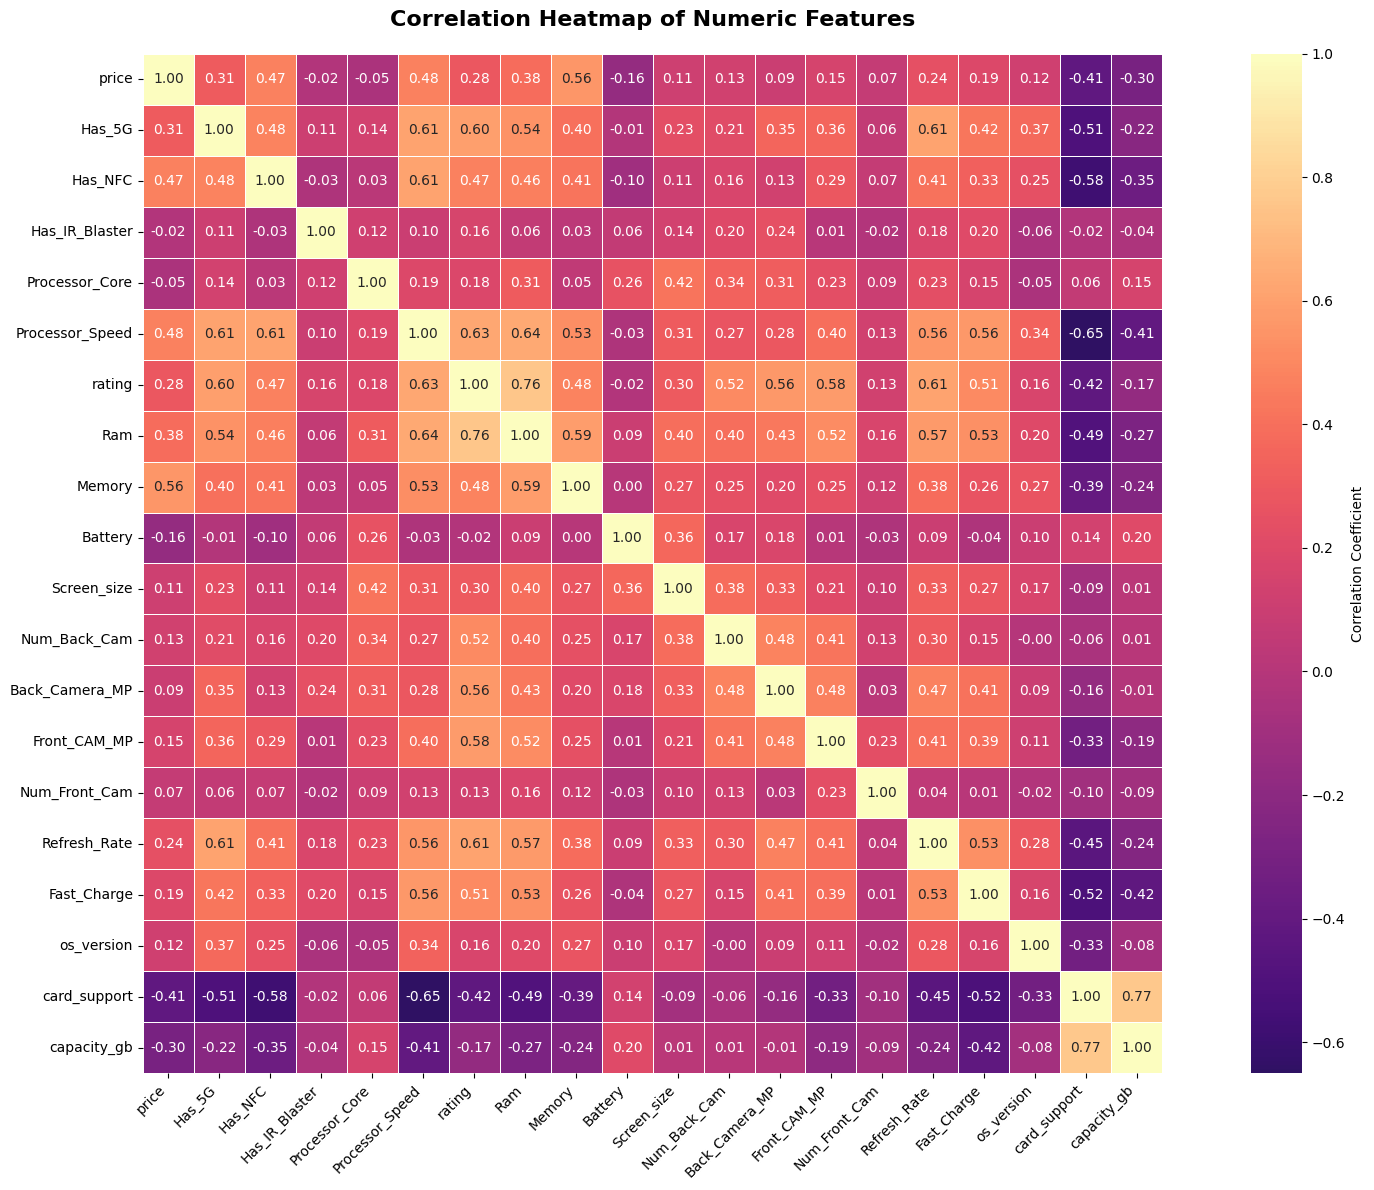

In [96]:


# Create correlation heatmap with improvements
plt.figure(figsize=(18, 12))
correlation = df.corr(numeric_only=True)

sns.heatmap(correlation, 
            annot=True,          
            fmt='.2f',            
            cmap='magma',     
            center=0,            
            square=True,          
            linewidths=0.5,       
            cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Correlation Heatmap of Numeric Features', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**What it does:** Extracts the correlation of every numeric column with `price`,
and re-runs `df.info()`.

**Insight:** The `.info()` re-check here is the key step — it shows which columns
still contain missing values at this point, setting up the imputation step that
follows.

In [97]:


a = df.corr(numeric_only=True)["price"].reset_index()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            981 non-null    str    
 1   model            981 non-null    str    
 2   price            981 non-null    int64  
 3   Has_5G           981 non-null    bool   
 4   Has_NFC          981 non-null    bool   
 5   Has_IR_Blaster   981 non-null    bool   
 6   Processor_Model  981 non-null    object 
 7   Processor_Name   981 non-null    str    
 8   Processor_Core   975 non-null    float64
 9   Processor_Speed  948 non-null    float64
 10  rating           879 non-null    float64
 11  Ram              978 non-null    float64
 12  Memory           981 non-null    float64
 13  Battery          970 non-null    float64
 14  Screen_size      981 non-null    float64
 15  Resolution       981 non-null    str    
 16  Num_Back_Cam     981 non-null    int64  
 17  Back_Camera_MP   981 non-nu

## 22. Missing Value Imputation

**What it does:** Uses `KNNImputer` (with `n_neighbors=5`) to fill missing values
in all numeric columns **except `price`** — for each missing value, it estimates a
replacement based on the 5 most similar rows (nearest neighbors) across the other
numeric features.

**Insight:** KNN imputation is a more informed alternative to simple mean/median
filling — it preserves relationships between features (e.g., a missing `rating`
for a phone is filled based on similar phones' ratings, not just the dataset-wide
average). `price` is deliberately excluded from imputation since it is the target
variable and should never be estimated from other features.

In [98]:
from sklearn.impute import KNNImputer
imputer  = KNNImputer(n_neighbors=5)
# 1. Get the list of column names
num_cols = list(df.select_dtypes(include=["float64", "int64"]).drop(columns=["price"], errors='ignore').columns)

# 2. Impute the DATA from those columns, not the names!
# Note: we use df[num_cols] inside the fit_transform
imputed_values = imputer.fit_transform(df[num_cols])

# 3. Assign back to the dataframe
df[num_cols] = imputed_values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            981 non-null    str    
 1   model            981 non-null    str    
 2   price            981 non-null    int64  
 3   Has_5G           981 non-null    bool   
 4   Has_NFC          981 non-null    bool   
 5   Has_IR_Blaster   981 non-null    bool   
 6   Processor_Model  981 non-null    object 
 7   Processor_Name   981 non-null    str    
 8   Processor_Core   981 non-null    float64
 9   Processor_Speed  981 non-null    float64
 10  rating           981 non-null    float64
 11  Ram              981 non-null    float64
 12  Memory           981 non-null    float64
 13  Battery          981 non-null    float64
 14  Screen_size      981 non-null    float64
 15  Resolution       981 non-null    str    
 16  Num_Back_Cam     981 non-null    float64
 17  Back_Camera_MP   981 non-nu

## 23. Feature Engineering — Encoding & Scaling

**What it does:**
1. Drops the first row of the dataframe (`df.index[0]`) — likely a leftover
   header/placeholder row.
2. Separates features (`X_raw`) from the target (`y = price`), dropping identifier
   columns (`model`, `Processor_Name`) that aren't useful as model inputs.
3. Splits the remaining columns into **categorical** (`object` dtype) and
   **numeric** (`float64` / `int64`) groups.
4. Builds a `ColumnTransformer` that applies `OneHotEncoder` (dropping the first
   category to avoid the dummy-variable trap) to categorical columns and
   `StandardScaler` to numeric columns, all in a single `fit_transform` step.

**Insight:** This is the standard scikit-learn pattern for mixed-type tabular
data — it converts categorical specs (Brand, OS, Processor_Model, etc.) into
numeric one-hot vectors and standardizes numeric specs (mean 0, std 1), so that
distance-based and regularized models (KNN, SVR, Ridge, ElasticNet) aren't biased
by features with different scales.

In [99]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Clean Data
df = df.drop(df.index[0]).reset_index(drop=True)

# 2. Identify Column Types
# We drop "price" from features, and also drop specific columns you don't want
X_raw = df.drop(columns=["model","Processor_Name", "price"])
y = df["price"]

cat_cols = list(X_raw.select_dtypes(include=['object']).columns)
num_cols = list(X_raw.select_dtypes(include=['float64', 'int64']).columns)

# 3. Setup the Transformer (One-Hot for categories, Scaling for numbers)
# This does EVERYTHING in one step!
ct = ColumnTransformer(transformers=[
    ('encoder', OneHotEncoder(drop='first', sparse_output=False), cat_cols),
    ('scaler', StandardScaler(), num_cols)
])

X_final = ct.fit_transform(X_raw)


## 24. Baseline Model Comparison

**What it does:**
1. Splits the transformed data into training (80%) and test (20%) sets.
2. Trains five regression models — **Linear Regression, Random Forest, Gradient
   Boosting, SVR, and K-Nearest Neighbors** — on the same split and prints each
   model's R² score on the test set.
3. Runs 5-fold cross-validation on the Random Forest model for a more robust
   performance estimate.

**Insight:** This establishes a performance baseline across different model
families (linear, tree-ensemble, kernel-based, instance-based) before any
hyperparameter tuning. Tree-based ensembles typically outperform Linear Regression
and SVR on tabular data with mixed categorical/numeric features and non-linear
relationships. The cross-validation step also checks that the Random Forest's
performance is stable across different data splits, rather than being a result of
one lucky train/test split.

In [100]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

# test_size=0.2 means 80% for training, 20% for testing
# random_state=42 acts as a "seed" so you get the same split every time you run it
X_train, X_test, y_train, y_test = train_test_split(
    X_final, 
    y, 
    test_size=0.2, 
    random_state=42
)
# Initialize the models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, 
    max_depth=10, 
    random_state=42,
    n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR (Support Vector)": SVR(kernel='rbf'),
    "K-Neighbors": KNeighborsRegressor(n_neighbors=5)
}

# Dictionary to store scores
results = {}

# Loop through each model, train, and predict
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    score = r2_score(y_test, predictions)
    results[name] = score
    print(f"{name} R2 Score: {score:.4f}")
    
    
from sklearn.model_selection import cross_val_score
rf_model = RandomForestRegressor(n_estimators=200, 
    max_depth=10, 
    random_state=42,
    n_jobs=-1)
# Test the model on 5 different "folds" of the data
cv_scores = cross_val_score(rf_model, X_final, y, cv=5)

print(f"All CV Scores: {cv_scores}")
print(f"Average CV Score: {cv_scores.mean():.4f}")

Linear Regression R2 Score: 0.7558
Random Forest R2 Score: 0.8481
Gradient Boosting R2 Score: 0.7852
SVR (Support Vector) R2 Score: -0.1344
K-Neighbors R2 Score: 0.7285
All CV Scores: [ -1.19449927  -6.56247776 -13.54663339 -90.57298986 -11.1838495 ]
Average CV Score: -24.6121


## 25. Extended Model Comparison — Boosting Algorithms

**What it does:** Re-scales the train/test features with `StandardScaler`, then
trains and evaluates five more models — **Ridge Regression, Elastic Net, Gradient
Boosting, XGBoost, and LightGBM** — printing each model's R² score in a formatted
table.

**Insight:** Adds regularized linear models (Ridge, Elastic Net) and two
industry-standard gradient-boosting libraries (XGBoost, LightGBM), which often
achieve the strongest results on structured/tabular prediction tasks. Comparing R²
across this wider set of algorithms is what justifies choosing XGBoost as the final
model in the next cell.

In [101]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 1. Scaling (Crucial for Ridge, ElasticNet, and SVR)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Define models with key parameters
models = {
    "Ridge Regression": Ridge(alpha=1.0), 
    "Elastic Net": ElasticNet(alpha=0.1, l1_ratio=0.5),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, subsample=0.8),
    "LightGBM": LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=31)
}

# 3. Train and Evaluate
print(f"{'Algorithm':<20} | {'R2 Score':<10}")
print("-" * 35)

for name, model in models.items():
    # Use scaled data for all to be safe
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    score = r2_score(y_test, y_pred)
    print(f"{name:<20} | {score:.4f}")

Algorithm            | R2 Score  
-----------------------------------
Ridge Regression     | 0.7648
Elastic Net          | 0.7938
Gradient Boosting    | 0.7680
XGBoost              | 0.9013
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000431 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 394
[LightGBM] [Info] Number of data points in the train set: 784, number of used features: 42
[LightGBM] [Info] Start training from score 32532.204082
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No furt

## 26. Final Model — XGBoost

**What it does:** Trains a final `XGBRegressor` (`n_estimators=260`,
`learning_rate=0.05`, `max_depth=5`, `subsample=0.8`) on the scaled training data,
then evaluates it on the test set using **MSE**, **RMSE**, and **R²**.

**Insight:** RMSE is reported in the same units as `price`, making it directly
interpretable — e.g., an RMSE of *X* means predictions are typically off by about
*X* currency units. This is the model that gets saved for deployment in Cell 60.

In [102]:
from sklearn.metrics import mean_squared_error
XGB_model  = XGBRegressor(n_estimators=260, learning_rate=0.05, max_depth=5, subsample=0.8)
XGB_model.fit(X_train_scaled, y_train)
y_pred = XGB_model.predict(X_test_scaled)
score = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")

# Often, we take the Square Root (RMSE) to get back to original units
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error: {rmse:.4f}")
print(f"R2 Score {score:.4f}")


Mean Squared Error: 59656462.8684
Root Mean Squared Error: 7723.7596
R2 Score 0.9031


## 27. Sanity-Check Prediction

**What it does:** Prints every feature value for a single record (row 900) from
the dataset, so we can manually inspect a real example before testing the
prediction pipeline on it.

In [103]:
print(df.loc[900])

Brand                     Vivo
model                Vivo Y15s
price                     8499
Has_5G                   False
Has_NFC                  False
Has_IR_Blaster           False
Processor_Model          Helio
Processor_Name           Helio
Processor_Core             8.0
Processor_Speed            2.3
rating                    66.0
Ram                        3.0
Memory                    32.0
Battery                 5000.0
Screen_size               6.51
Resolution         720 x 1600 
Num_Back_Cam               2.0
Back_Camera_MP            13.0
Front_CAM_MP               8.0
Num_Front_Cam              1.0
Refresh_Rate              60.0
Fast_Charge               11.0
OS_Name                android
os_version                11.0
card_support               1.0
slot_type            Dedicated
capacity_gb             1024.0
Name: 900, dtype: object


**What it does:** Takes a single raw record (row 10) from `X_raw`, runs it through
the **same** `ColumnTransformer` (`ct`) used during training to encode/scale it
identically, feeds it to the trained `XGB_model`, and compares the predicted price
to the actual price.

**Insight:** This end-to-end test confirms the saved preprocessing + model pipeline
reproduces a consistent prediction on a real record — exactly the workflow the
deployed app will use when a user submits phone specs.

In [104]:
p = 10
# 1. Get the raw row from your features (X)
# We use loc[p:p] to keep it as a DataFrame, which the transformer needs
raw_row = X_raw.loc[p:p]

# 2. Use the ColumnTransformer (ct) to encode AND scale in one go
scaled_row = ct.transform(raw_row)

# 3. Predict
prediction = XGB_model.predict(scaled_row)

print(f"The Predicted Price is: {prediction[0]:.2f}")
print(f"Actual Price was: {y.iloc[p]}")

The Predicted Price is: 152282.84
Actual Price was: 162990


**What it does:** Lists the column names of `raw_row` — i.e., the exact set of
input features the model expects. Useful as a reference when designing the input
form for the deployment app.

In [105]:
raw_row.columns

Index(['Brand', 'Has_5G', 'Has_NFC', 'Has_IR_Blaster', 'Processor_Model',
       'Processor_Core', 'Processor_Speed', 'rating', 'Ram', 'Memory',
       'Battery', 'Screen_size', 'Resolution', 'Num_Back_Cam',
       'Back_Camera_MP', 'Front_CAM_MP', 'Num_Front_Cam', 'Refresh_Rate',
       'Fast_Charge', 'OS_Name', 'os_version', 'card_support', 'slot_type',
       'capacity_gb'],
      dtype='str')

**What it does:** Displays the final transformed feature matrix `X_final` — the
fully encoded and scaled array that was actually fed into the models.

In [106]:
X_final

array([[ 0.        ,  0.        ,  0.        , ..., -1.58404931,
        -1.28959043, -0.98988177],
       [ 0.        ,  0.        ,  0.        , ..., -5.42116308,
         0.77544   , -0.44209211],
       [ 0.        ,  0.        ,  0.        , ..., -0.94453035,
         0.77544   , -0.44209211],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -4.07817326,
         0.77544   , -0.85293436],
       [ 0.        ,  0.        ,  0.        , ..., -4.07817326,
         0.77544   , -0.85293436],
       [ 0.        ,  0.        ,  0.        , ..., -1.58404931,
         0.77544   , -0.71598694]])

## 28. Building a Lookup Table for the App

**What it does:** Groups the data by `Processor_Name` and builds a dictionary
mapping each processor name to its corresponding `Processor_Core` and
`Processor_Speed` values.

**Insight:** This lookup table lets the deployment app **auto-fill** technical
fields (core count, clock speed) once a user selects a processor name from a
dropdown — improving UX by reducing the number of fields a user has to fill in
manually.

In [107]:
# From your training data
processor_lookup = df.groupby('Processor_Name')[['Processor_Core', 'Processor_Speed']].first().to_dict('index')

# camera_lookup = df.groupby('original_camera_col')[['Num_Back_Cam', 'Back_Camera_MP', 'Num_Front_Cam', 'Front_CAM_MP']].first().to_dict('index')
processor_lookup

{'Bionic A': {'Processor_Core': 4.0, 'Processor_Speed': 2.37},
 'Bionic A13': {'Processor_Core': 6.0, 'Processor_Speed': 2.65},
 'Bionic A14': {'Processor_Core': 6.0, 'Processor_Speed': 3.1},
 'Bionic A15': {'Processor_Core': 6.0, 'Processor_Speed': 3.22},
 'Bionic A16': {'Processor_Core': 6.0, 'Processor_Speed': 3.148},
 'Bionic A17': {'Processor_Core': 8.0, 'Processor_Speed': 2.8800000000000003},
 'Dimensity 1000+': {'Processor_Core': 8.0, 'Processor_Speed': 2.6},
 'Dimensity 1080': {'Processor_Core': 8.0, 'Processor_Speed': 2.6},
 'Dimensity 1100 5G': {'Processor_Core': 8.0, 'Processor_Speed': 2.6},
 'Dimensity 1200': {'Processor_Core': 8.0, 'Processor_Speed': 3.0},
 'Dimensity 1200 Max': {'Processor_Core': 8.0, 'Processor_Speed': 3.0},
 'Dimensity 1300': {'Processor_Core': 8.0, 'Processor_Speed': 3.0},
 'Dimensity 700': {'Processor_Core': 8.0, 'Processor_Speed': 2.2},
 'Dimensity 700 5G': {'Processor_Core': 8.0, 'Processor_Speed': 2.2},
 'Dimensity 720': {'Processor_Core': 8.0, 'Pr

**What it does:** Final preview of the cleaned dataframe before export, confirming
the columns and values look correct.

In [108]:
df.head(1)

,Brand,model,price,Has_5G,Has_NFC,Has_IR_Blaster,Processor_Model,Processor_Name,Processor_Core,Processor_Speed,rating,Ram,Memory,Battery,Screen_size,Resolution,Num_Back_Cam,Back_Camera_MP,Front_CAM_MP,Num_Front_Cam,Refresh_Rate,Fast_Charge,OS_Name,os_version,card_support,slot_type,capacity_gb
0,Xiaomi,Xiaomi Redmi K20 Pro Signature Edition,480000,False,True,False,Snapdragon,Snapdragon 855,8.0,2.8,88.0,8.0,256.0,4000.0,6.39,1080 x 2340,3.0,48.0,20.0,1.0,60.0,27.0,android,9.0,0.0,Not Slot,0.0


## 29. Exporting Model Artifacts for Deployment

**What it does:**
1. Saves the fitted `ColumnTransformer` (`ct`) and the trained `XGBRegressor`
   (`XGB_model`) as pickle files (`ct.pkl`, `model.pkl`) inside an `app/model/`
   directory.
2. Drops the `price` and `model` columns from `df` (the app needs neither the
   target nor the identifier) and saves the remaining cleaned data to
   `app/data/data.csv`.

**Insight:** This is the hand-off point from the notebook (research/experimentation)
to a production app (e.g., Flask / FastAPI / Streamlit). Saving the fitted
transformer alongside the model ensures any new user input is preprocessed
**exactly** the same way as the training data — critical for correct predictions.

In [109]:
import pickle

# Save both
with open("../app/model/ct.pkl", "wb") as f:
    pickle.dump(ct, f)

with open("../app/model/model.pkl", "wb") as f:
    pickle.dump(XGB_model, f)

print("Saved ct.pkl and model.pkl")

df.drop(columns=["price","model"],inplace=True)
df.to_csv("../app/data/data.csv")

Saved ct.pkl and model.pkl


**What it does:** Lists the final column names of the exported dataframe — the
schema the deployment app's backend will work with.

In [110]:
df.columns

Index(['Brand', 'Has_5G', 'Has_NFC', 'Has_IR_Blaster', 'Processor_Model',
       'Processor_Name', 'Processor_Core', 'Processor_Speed', 'rating', 'Ram',
       'Memory', 'Battery', 'Screen_size', 'Resolution', 'Num_Back_Cam',
       'Back_Camera_MP', 'Front_CAM_MP', 'Num_Front_Cam', 'Refresh_Rate',
       'Fast_Charge', 'OS_Name', 'os_version', 'card_support', 'slot_type',
       'capacity_gb'],
      dtype='str')

## 30. Generating Reference Values for the App's UI

**What it does:** Prints the unique (or sorted unique) values for every key
categorical and numeric column — brands, processor models/names, resolutions, OS
names, slot types, RAM/storage/battery/screen-size options, camera specs, etc.

**Insight:** These value lists become the dropdown/select-box options in the
deployment app's input form, ensuring users can only submit spec combinations that
actually exist in the training data — keeping predictions within the model's
learned range and avoiding invalid inputs.

In [111]:
# Run all of these
print("Brands:", df["Brand"].unique().tolist())
print("Processor_Model:", df["Processor_Model"].unique().tolist())
print("Processor_Name:", df["Processor_Name"].unique().tolist())
print("Resolution:", df["Resolution"].unique().tolist())
print("OS_Name:", df["OS_Name"].unique().tolist())
print("slot_type:", df["slot_type"].unique().tolist())
print("Ram:", sorted(df["Ram"].unique().tolist()))
print("Memory:", sorted(df["Memory"].unique().tolist()))
print("Battery:", sorted(df["Battery"].unique().tolist()))
print("Screen_size:", sorted(df["Screen_size"].unique().tolist()))
print("Refresh_Rate:", sorted(df["Refresh_Rate"].unique().tolist()))
print("Back_Camera_MP:", sorted(df["Back_Camera_MP"].unique().tolist()))
print("Front_CAM_MP:", sorted(df["Front_CAM_MP"].unique().tolist()))
print("Num_Back_Cam:", sorted(df["Num_Back_Cam"].unique().tolist()))
print("Num_Front_Cam:", sorted(df["Num_Front_Cam"].unique().tolist()))

Brands: ['Xiaomi', 'Huawei', 'Apple', 'Samsung', 'Royole', 'Sony', 'Oppo', 'Leitz', 'Vivo', 'Asus', 'Honor', 'Google', 'Lg', 'Oneplus', 'Tesla', 'Iqoo', 'Zte', 'Nubia', 'Motorola', 'Lenovo', 'Sharp', 'Tecno', 'Nokia', 'Realme', 'Doogee', 'Poco', 'Nothing', 'Infinix', 'Oukitel', 'Redmi', 'Lava', 'Cat', 'Cola', 'Blu', 'Jio', 'Leeco', 'Duoqin', 'Blackview', 'Tcl', 'Ikall', 'Micromax', 'Gionee', 'Letv', 'Itel', 'Lyf']
Processor_Model: ['Snapdragon', 'Kirin', 'Bionic', 'Dimensity', 'Exynos', 'Tensor', 'Tesla', 'Helio', 'Unisoc']
Processor_Name: ['Snapdragon 855', 'Snapdragon 8+ Gen1', 'Kirin 990', 'Snapdragon 855+', 'Bionic A16', 'Bionic A15', 'Snapdragon 888', 'Bionic A17', 'Bionic A14', 'Snapdragon 865', 'Snapdragon 8 Gen1', 'Snapdragon 8+ Gen 2', 'Snapdragon 8 Gen2', 'Bionic A13', 'Dimensity 9000', 'Exynos 2100', 'Exynos 990', 'Kirin 9000E', 'Exynos 9825', 'Tensor G2', 'Tensor', 'Exynos 9820', 'Tensor 3', 'Tesla Custom Chip', 'Kirin 9000', 'Dimensity 9200', 'Exynos 2200', 'Snapdragon 765

---

## 📌 Project Summary

- Performed a full EDA on a smartphone specifications dataset (~980 phones):
  univariate analysis of price, ratings, and hardware specs; bivariate analysis of
  how brand, processor, 5G, NFC, and IR Blaster relate to price and rating.
- Cleaned messy categorical data (processor names, OS names, brand casing) and
  handled missing ratings/specs via KNN imputation.
- Built a preprocessing pipeline (`OneHotEncoder` + `StandardScaler` via
  `ColumnTransformer`) and benchmarked **10 regression algorithms**
  (Linear, Ridge, Elastic Net, SVR, KNN, Random Forest, Gradient Boosting, XGBoost,
  LightGBM).
- Selected **XGBoost** as the final model and exported it along with the
  preprocessing transformer and reference data for a deployment app.

### Possible Improvements
- Replace the `inplace=True` + reassignment pattern (flagged in several cells)
  with the safer `df['col'] = df['col'].replace({...})` form.
- Hyperparameter-tune the final XGBoost model (e.g., with `GridSearchCV` or
  `Optuna`) for a further R² boost.
- Add a `requirements.txt` and a short `README.md` describing how to run the
  notebook and the deployment app — useful when sharing this project in a
  portfolio or on GitHub.